# 11 - Does the quantum advantage survive the device? (week 3)
Owner: **Shams**

Our only quantum advantage is the projected kernel on **engineered labels at $n=6$** (notebook 05): labels built from the direction where the quantum and classical kernels differ most. It was measured in perfect simulation. Here we ask the professor's question, *do we see something on a real device?*

**Fixed protocol (set before looking at any result):**
- **Same task as notebook 05:** same images, same engineered labels ($\lambda = 0.1, 0.01, 0.001$), same best classical model $C^\ast$ (from notebook 05, 28/7-setting budgets, untouched).
- **Quantum levels**, all with $\alpha = 1$ (chosen by tuning in all 15 $n=6$ engineered runs, and the only $\alpha$ the hardware could afford):
  1. *ideal (sampled)*: notebook 05's result, 2048 shots, no device errors;
  2. *noise model*: `FakeKingston`, the same 362 transpiled circuits as the hardware, all 5 seeds;
  3. *noise model + readout mitigation*;
  4. *real hardware* `ibm_kingston` (notebook 10), seeds 0 and 100;
  5. *real hardware + readout mitigation*.
- **Each level is re-tuned on its own training features**: $\gamma$ scale $\in\{0.5, 2\}$ $\times$ 7 values of $C$ by inner CV on the training images, then one test score. This is what an engineer would do on a device. The ideal level is taken from notebook 05, where tuning chose $\alpha=1$ in every run, so it used exactly these 14 settings (asserted below).
- **Readout mitigation** (`hardware.mitigate_readout`): per qubit, invert $\langle P\rangle_{\text{meas}} = (1-p_{10}-p_{01})\langle P\rangle + (p_{01}-p_{10})$ using the 2 calibration circuits of the same run.
- **Falsifier, unchanged:** improvement if mean $\Delta A = A^Q - A^{C^\ast}$ over the 5 seeds exceeds its standard deviation. With 2 hardware seeds we report each seed and do not apply the falsifier.

In [1]:
import sys, json, time
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from qiskit_ibm_runtime.fake_provider import FakeKingston
from src.common import (get_split, make_preprocessor, encoding_circuit, inner_folds,
                        cv_score_precomputed, evaluate_precomputed, result_path, RESULTS, SEEDS, SHOTS)
from src.projected import projected_kernel, median_gamma, GAMMA_SCALES, C_GRID
from src.baselines import classical_gram
from src.geometry import geometric_difference
from src.engineered import generator_kernels, engineered_labels, GEN_LAMBDAS
from src.hardware import (build_circuits, transpile_for, dry_run_counts, features_from_counts,
                          readout_errors, mitigate_readout, save_counts, load_counts)

## 1. Settings and helpers

In [2]:
N, LAYERS, ALPHA = 6, 2, 1.0
HW_SEEDS = [0, 100]
KINDS = {"SVM RBF (tuned)": "rbf", "SVM polynomial (tuned)": "poly", "SVM linear (tuned)": "linear"}
lam_tag = lambda lam: f"{lam:g}".replace(".", "p")
LEVELS = ["ideal (sampled)", "noise model", "noise model + mitigation", "hardware", "hardware + mitigation"]
fake = FakeKingston()
enc = encoding_circuit(N, LAYERS)

def features(counts, n_all):
    # raw and readout-mitigated Pauli features + readout errors, from one run's counts
    F = features_from_counts(counts[:3 * n_all], n_all, N)
    p10, p01 = readout_errors(counts[3 * n_all], counts[3 * n_all + 1], N)
    return F, mitigate_readout(F, p10, p01), p10, p01

def tune_eval(F_all, n_tr, ytr, yte, folds):
    # same 14 settings for every level (alpha fixed at 1): gamma scale x C, inner CV, one test score
    Ftr, Fte = F_all[:n_tr], F_all[n_tr:]
    best = dict(score=-1)
    for gs in GAMMA_SCALES:
        gam = median_gamma(Ftr, gs)
        K = projected_kernel(Ftr, gamma=gam)
        for C in C_GRID:
            s = cv_score_precomputed(K, ytr, folds, C)
            if s > best["score"]:
                best = dict(score=s, gscale=gs, gamma=gam, C=C)
    K = projected_kernel(Ftr, gamma=best["gamma"])
    res = evaluate_precomputed(K, projected_kernel(Fte, Ftr, gamma=best["gamma"]), ytr, yte, best["C"])
    return dict(best=best, **res), K

## 2. Noise-model and hardware features (about 1-2 minutes)
Noise-model counts come from the same transpiled circuits as the hardware (`hardware.dry_run_counts`). Seeds 0 and 100 reuse notebook 10's dry runs; the other seeds are run here and saved under the same name.

In [3]:
feats = {}
t0 = time.time()
for seed in SEEDS:
    Xtr, ytr0, Xte, yte0 = get_split(seed)
    tf = make_preprocessor(N, ALPHA)(Xtr)                   # fitted on training images only
    A_all = np.vstack([tf(Xtr), tf(Xte)])
    n_all = len(A_all)
    path = result_path("hardware", "dryrun_counts_a1", seed, N, "json")
    if path.exists():
        counts = load_counts(path)[3]
    else:
        tc = transpile_for(fake, build_circuits(enc, A_all), N)
        counts = dry_run_counts(fake, tc, seed=seed)
        save_counts(path, "local-dry-run", "FakeKingston", counts, dict(seed=seed, n=N, alpha=ALPHA, shots=SHOTS))
    F, Fm, p10, p01 = features(counts, n_all)
    feats[seed] = {"noise model": F, "noise model + mitigation": Fm, "noise_readout": (p10, p01)}
    hw_path = result_path("hardware", "hw_counts_a1", seed, N, "json")
    if hw_path.exists():
        job_id, backend_name, _, counts = load_counts(hw_path)
        F, Fm, p10, p01 = features(counts, n_all)
        feats[seed].update({"hardware": F, "hardware + mitigation": Fm, "hw_readout": (p10, p01), "job": job_id})
print(f"features ready in {time.time() - t0:.0f} s; hardware seeds available: "
      f"{[s for s in SEEDS if 'hardware' in feats[s]]}")

features ready in 42 s; hardware seeds available: [0]


## 3. Train and test every level on the engineered labels

In [4]:
runs = []
for seed in SEEDS:
    Xtr, ytr0, Xte, yte0 = get_split(seed)
    n_tr = len(Xtr)
    KC_gen, KQ_gen = generator_kernels(np.vstack([Xtr, Xte]), N)       # same labels as notebook 05
    Fc = make_preprocessor(N, 1.0)(Xtr)(Xtr)                             # classical features, as notebook 01
    for lam in GEN_LAMBDAS:
        lab, gen = engineered_labels(KC_gen, KQ_gen, lam)
        ytr, yte = lab[:n_tr], lab[n_tr:]
        e = json.loads(result_path("tables", f"engineered_lam{lam_tag(lam)}", seed, N, "json").read_text())
        assert e["train_pos"] == int((ytr == 1).sum()), "labels differ from notebook 05"
        assert e["projected"]["best"]["alpha"] == ALPHA, "notebook 05 did not choose alpha = 1 here"
        folds = inner_folds(ytr, seed)
        acc_c = e["acc_c_star"]
        KC = classical_gram(KINDS[e["c_star"]], e["baselines"][e["c_star"]]["params"], Fc)
        out = dict(seed=seed, n_qubits=N, lam=lam, c_star=e["c_star"], acc_c_star=acc_c,
                   levels={"ideal (sampled)": dict(acc=e["projected"]["sampled"]["acc"],
                                                   delta_A=e["delta_A"], best=e["projected"]["best"])})
        for lv in LEVELS[1:]:
            if lv not in feats[seed]:
                continue
            r, K = tune_eval(feats[seed][lv], n_tr, ytr, yte, folds)
            r.update(delta_A=r["acc"] - acc_c, g=geometric_difference(KC, K)[0],
                     bloch=float(np.linalg.norm(feats[seed][lv], axis=-1).mean()))
            out["levels"][lv] = r
        for key in ("noise_readout", "hw_readout"):
            if key in feats[seed]:
                out[key] = [v.tolist() for v in feats[seed][key]]
        if "job" in feats[seed]:
            out["hardware_job"] = feats[seed]["job"]
        result_path("tables", f"advantage_noise_lam{lam_tag(lam)}", seed, N, "json").write_text(
            json.dumps(out, indent=2, default=str))
        runs.append(out)
print(f"{len(runs)} runs done (5 seeds x 3 lambdas)")

15 runs done (5 seeds x 3 lambdas)


## 4. Results: 5 seeds (ideal vs noise model)

In [5]:
def vals(rows, lv, key):
    return np.array([r["levels"][lv][key] for r in rows if lv in r["levels"]], float)

for lam in GEN_LAMBDAS:
    rows = [r for r in runs if r["lam"] == lam]
    print(f"=== engineered labels, lambda = {lam:g}, n = {N}: mean +- std over {len(rows)} seeds ===")
    print(f"{'':<28}{'test acc':>16}{'Delta A':>18}   falsifier")
    c = np.array([r["acc_c_star"] for r in rows])
    print(f"{'best classical C*':<28}{c.mean():>8.3f} +-{c.std():.3f}")
    for lv in LEVELS[:3]:
        a, d = vals(rows, lv, "acc"), vals(rows, lv, "delta_A")
        verdict = "improvement" if d.mean() > d.std() else "no improvement"
        print(f"{lv:<28}{a.mean():>8.3f} +-{a.std():.3f}{d.mean():>+10.3f} +-{d.std():.3f}   {verdict}")
    print()

=== engineered labels, lambda = 0.1, n = 6: mean +- std over 5 seeds ===
                                    test acc           Delta A   falsifier
best classical C*              0.775 +-0.069
ideal (sampled)                0.825 +-0.061    +0.050 +-0.035   improvement
noise model                    0.820 +-0.066    +0.045 +-0.040   improvement
noise model + mitigation       0.815 +-0.058    +0.040 +-0.030   improvement

=== engineered labels, lambda = 0.01, n = 6: mean +- std over 5 seeds ===
                                    test acc           Delta A   falsifier
best classical C*              0.685 +-0.025
ideal (sampled)                0.760 +-0.058    +0.075 +-0.057   improvement
noise model                    0.780 +-0.060    +0.095 +-0.062   improvement
noise model + mitigation       0.765 +-0.090    +0.080 +-0.089   no improvement

=== engineered labels, lambda = 0.001, n = 6: mean +- std over 5 seeds ===
                                    test acc           Delta A   falsif

## 5. Results: real hardware seeds (one number per seed, no falsifier)

In [6]:
hw_rows = [r for r in runs if "hardware" in r["levels"]]
if not hw_rows:
    print("no hardware counts yet - run notebook 10 first (sections 4 and 5)")
for lam in GEN_LAMBDAS:
    rows = [r for r in hw_rows if r["lam"] == lam]
    if not rows:
        continue
    print(f"=== lambda = {lam:g}: test accuracy (Delta A vs C*) ===")
    print(f"{'level':<28}" + "".join(f"{'seed ' + str(r['seed']):>18}" for r in rows))
    print(f"{'best classical C*':<28}" + "".join(f"{r['acc_c_star']:>18.3f}" for r in rows))
    for lv in LEVELS:
        print(f"{lv:<28}" + "".join(f"{r['levels'][lv]['acc']:>9.3f} ({r['levels'][lv]['delta_A']:+.3f})"
                                    for r in rows))
    print()
for r in hw_rows[::len(GEN_LAMBDAS)]:
    p10, p01 = r["hw_readout"]
    print(f"seed {r['seed']} hardware job {r['hardware_job']}: readout p(1|0) {np.round(p10, 3)}, p(0|1) {np.round(p01, 3)}")

=== lambda = 0.1: test accuracy (Delta A vs C*) ===
level                                   seed 0
best classical C*                        0.900
ideal (sampled)                 0.900 (+0.000)
noise model                     0.900 (+0.000)
noise model + mitigation        0.900 (+0.000)
hardware                        0.850 (-0.050)
hardware + mitigation           0.850 (-0.050)

=== lambda = 0.01: test accuracy (Delta A vs C*) ===
level                                   seed 0
best classical C*                        0.725
ideal (sampled)                 0.850 (+0.125)
noise model                     0.850 (+0.125)
noise model + mitigation        0.875 (+0.150)
hardware                        0.800 (+0.075)
hardware + mitigation           0.800 (+0.075)

=== lambda = 0.001: test accuracy (Delta A vs C*) ===
level                                   seed 0
best classical C*                        0.725
ideal (sampled)                 0.825 (+0.100)
noise model                     0.825 (+

## 6. Feature quality: how much the device shrinks the 1-RDMs, and what mitigation recovers
Mean Bloch length of the 1-qubit states (1 = pure, 0 = maximally mixed) and mean $g$ of each level's kernel against $C^\ast$ ($\lambda = 0.1$ labels).

In [7]:
rows = [r for r in runs if r["lam"] == GEN_LAMBDAS[0]]
print(f"{'level':<28}{'Bloch length':>14}{'g vs C*':>10}{'seeds':>7}")
for lv in LEVELS[1:]:
    b, g = vals(rows, lv, "bloch"), vals(rows, lv, "g")
    if len(b):
        print(f"{lv:<28}{b.mean():>14.3f}{g.mean():>10.2f}{len(b):>7}")
p10 = np.mean([r["noise_readout"][0] for r in rows], axis=0)
print("\nnoise model readout p(1|0) per qubit (mean over seeds):", np.round(p10, 3))

level                         Bloch length   g vs C*  seeds
noise model                          0.584      2.85      5
noise model + mitigation             0.633      2.98      5
hardware                             0.668      2.11      1
hardware + mitigation                0.670      2.11      1

noise model readout p(1|0) per qubit (mean over seeds): [0.01  0.168 0.008 0.008 0.014 0.006]


## 7. Figure: $\Delta A$ per level (bars: 5-seed mean $\pm$ std; dots: hardware seeds)

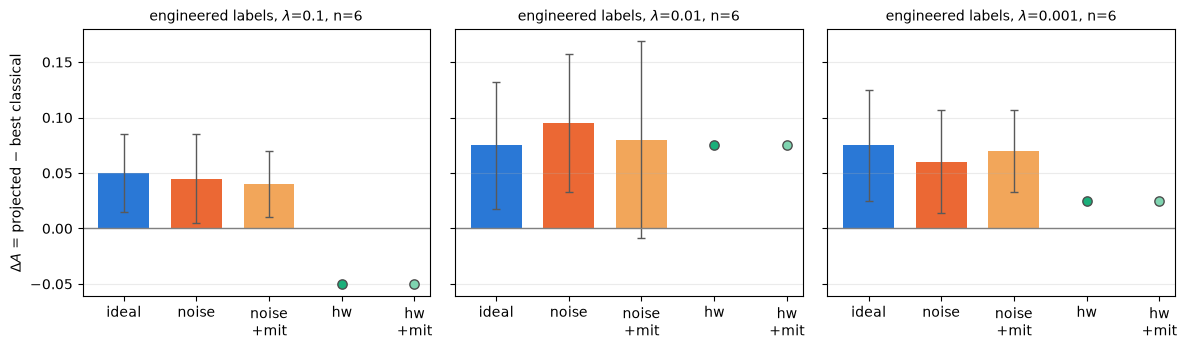

saved advantage_under_noise.png


In [8]:
figdir = RESULTS / "figures"
figdir.mkdir(parents=True, exist_ok=True)
cols = {"ideal (sampled)": "#2a78d6", "noise model": "#eb6834", "noise model + mitigation": "#f2a65a",
        "hardware": "#1baf7a", "hardware + mitigation": "#7fd4b0"}
fig, axes = plt.subplots(1, len(GEN_LAMBDAS), figsize=(12, 3.6), sharey=True)
for ax, lam in zip(axes, GEN_LAMBDAS):
    rows = [r for r in runs if r["lam"] == lam]
    for i, lv in enumerate(LEVELS):
        d = vals(rows, lv, "delta_A")
        if lv.startswith("hardware"):
            ax.scatter(np.full(len(d), i), d, color=cols[lv], s=45, zorder=3, edgecolor="0.3",
                       label="hardware seeds" if i == 3 else None)
        else:
            ax.bar(i, d.mean(), 0.7, yerr=d.std(), color=cols[lv], capsize=3,
                   error_kw=dict(elinewidth=1, ecolor="0.35"))
    ax.axhline(0, color="0.5", linewidth=1)
    ax.set_xticks(range(len(LEVELS)), ["ideal", "noise", "noise\n+mit", "hw", "hw\n+mit"])
    ax.set_title(f"engineered labels, $\\lambda$={lam:g}, n={N}", fontsize=10)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel(r"$\Delta A$ = projected $-$ best classical")
fig.tight_layout()
fig.savefig(figdir / "advantage_under_noise.png", dpi=200)
plt.show()
print("saved advantage_under_noise.png")